# 21 · Context from other posts, text embeddings, offset target (E49-E51)

- **E49** features from other posts of the same author, hashtags and brand, from all 12,500 mentions, without any view counts (leave-self-out);
- **E50** local sentence embeddings (`multilingual-e5-small`, PCA 16) and TF-IDF SVD 16, with reactions and without;
- **E51** offset target: learn log10(views) − log10(likes + 1).

Base: final model (CatBoost MAE on followers + reactions + flags). 5-fold brand-grouped CV, paired brand bootstrap CI. Text never leaves homelab3.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30)
import extra_models as em, history as H, context_text as ct

In [2]:
f, meta = em.load(ROOT)
C = ct.context(ROOT)
E = ct.embeddings(ROOT, ROOT / "data" / "processed" / "embeddings_e5_cache.pkl")
pe, ts = ct.reduce(E, ROOT)
C.loc[meta.index].groupby(meta.platform.values).median().T.round(2)

,tiktok,twitter,youtube
author_posts,0.69,0.69,0.69
author_brands,1.00,1.00,1.00
author_mean_likes,2.66,0.00,1.88
likes_vs_author,0.00,0.00,0.00
n_hashtags,5.00,0.00,1.00
hashtag_max_freq,2.56,0.00,0.69
hashtag_mean_likes,2.85,2.14,2.14
brand_platform_posts,2.40,2.40,2.71
brand_mean_likes,3.74,0.39,2.56
brand_mean_followers,3.18,2.71,4.54


In [3]:
P = ct.run(f, meta, C, pe, ts); S = H.summarise(P)
S.pivot(index="model", columns="platform", values="MAE")[ct.PLATS].loc[S.model.unique()].round(3)

platform,tiktok,youtube,twitter
model,,,
final model,0.273,0.456,0.466
+ author,0.274,0.452,0.463
+ hashtags,0.275,0.459,0.468
+ brand,0.274,0.469,0.474
+ copies,0.272,0.458,0.468
+ all context,0.274,0.464,0.469
+ embeddings,0.270,0.465,0.455
+ TF-IDF,0.276,0.462,0.464
offset target,0.272,0.449,0.466


In [4]:
pairs = [("final model", k) for k in S.model.unique() if not k.startswith("no reactions") and k != "final model"] + [("no reactions: followers", k) for k in S.model.unique() if k.startswith("no reactions:") and k != "no reactions: followers"]
G = pd.DataFrame([{"platform": p, "base": a, "model": b, **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P, p, a, b)))} for p in ct.PLATS for a, b in pairs]); G.round(3)

,platform,base,model,gain,CI low,CI high
0,tiktok,final model,+ author,-0.001,-0.003,0.002
1,tiktok,final model,+ hashtags,-0.002,-0.004,-0.000
2,tiktok,final model,+ brand,-0.001,-0.004,0.002
3,tiktok,final model,+ copies,0.001,-0.001,0.003
4,tiktok,final model,+ all context,-0.000,-0.004,0.003
5,tiktok,final model,+ embeddings,0.003,-0.001,0.007
6,tiktok,final model,+ TF-IDF,-0.003,-0.006,0.000
7,tiktok,final model,offset target,0.001,-0.002,0.004
8,tiktok,final model,offset target + all context,-0.002,-0.007,0.003
9,tiktok,no reactions: followers,no reactions: + embeddings,0.009,0.003,0.016


In [5]:
F5 = ct.fifths(P); F5.pivot_table(index=["platform", "fifth"], columns="model", values="bias", sort=False).round(3)

model             final model  offset target
platform fifth                              
tiktok   lowest         0.275          0.246
         2              0.039          0.042
         3             -0.058         -0.056
         4             -0.133         -0.129
         highest       -0.223         -0.210
youtube  lowest         0.491          0.457
         2              0.057          0.043
         3             -0.048         -0.055
         4             -0.242         -0.237
         highest       -0.456         -0.441
twitter  lowest         0.629          0.622
         2              0.206          0.207
         3             -0.079         -0.077
         4             -0.369         -0.365
         highest       -0.585         -0.569

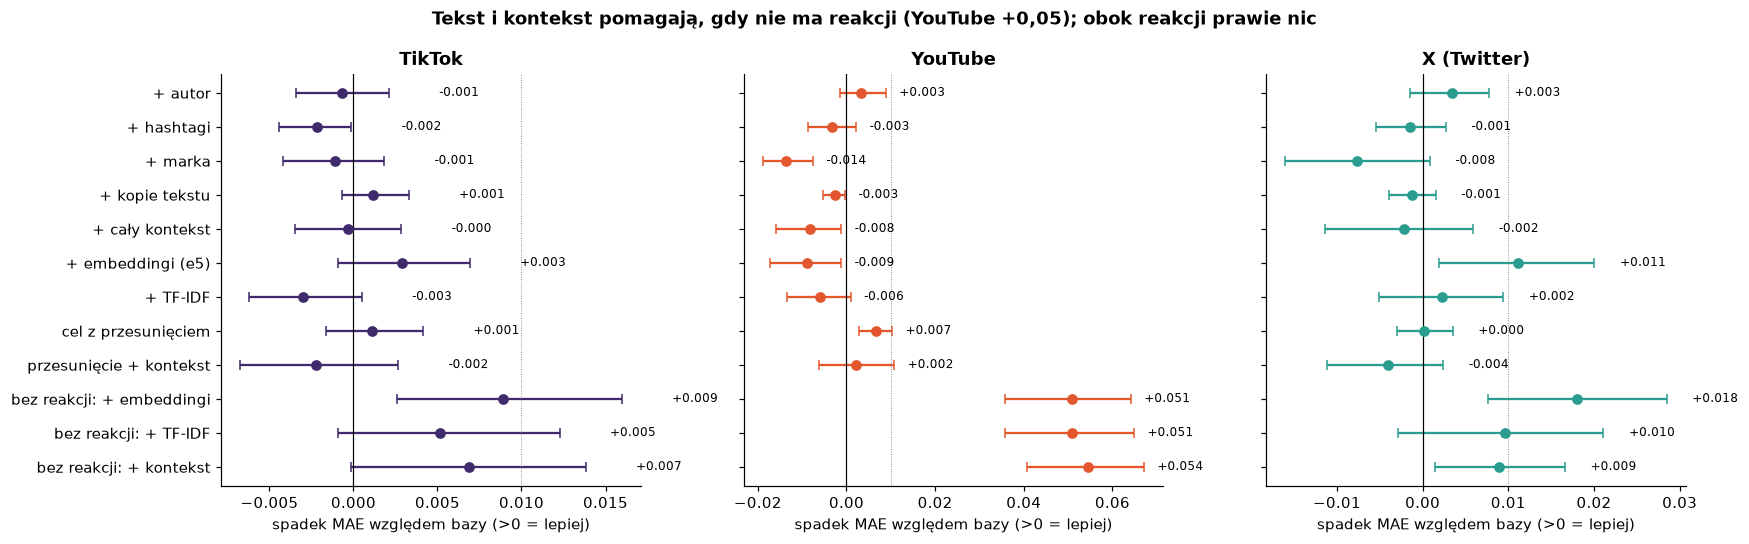

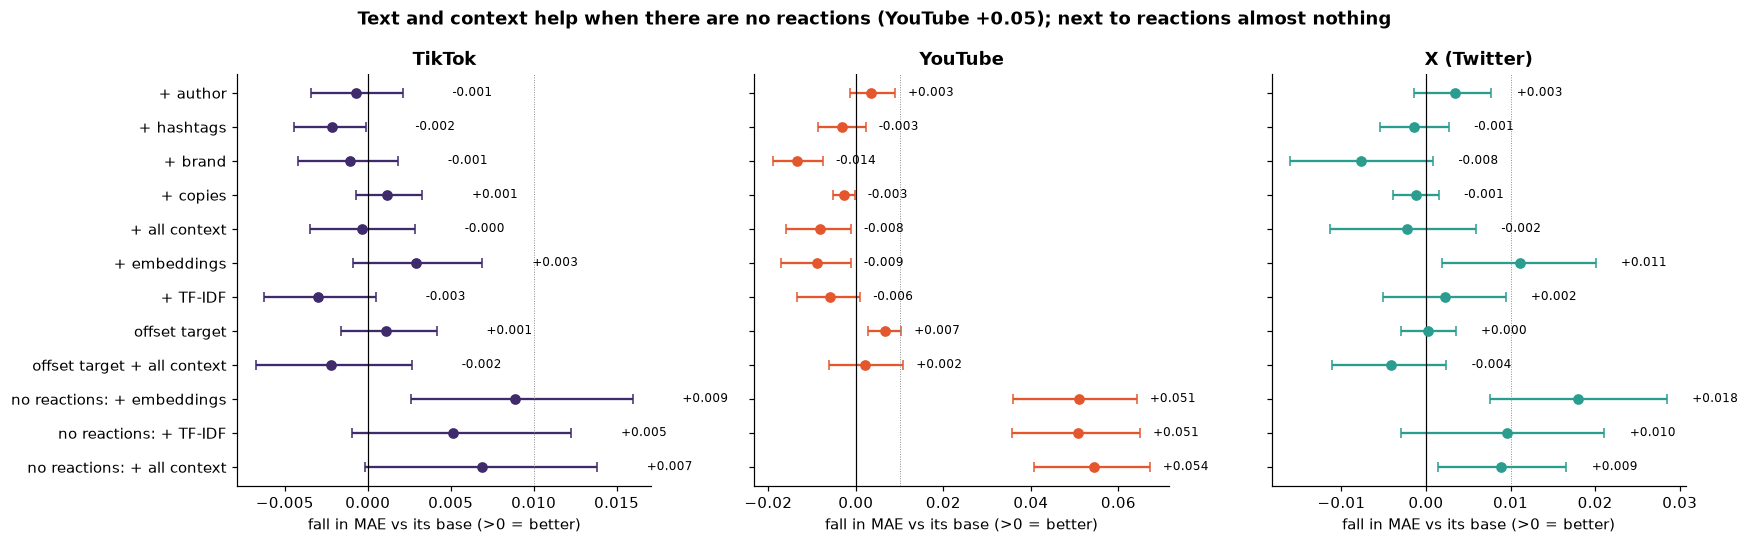

In [6]:
for l in ("pl", "en"): ct.plot_gains(G, FIG / f"context_text_{l}.png", l)

## Takeaways
See `docs/en/experiments.md` (E49-E51) and the vault cards. Numbers: `data/processed/context_text_numbers.json`.

In [7]:
json.dump({"models": S.to_dict("records"), "gains": G.to_dict("records"), "fifths": F5.astype({"fifth": str}).to_dict("records")},
          open(ROOT / "data" / "processed" / "context_text_numbers.json", "w"), indent=1, default=float)